<a href="https://colab.research.google.com/github/odoalawaye/Pytorch-Tutorial/blob/main/Linear_Regression_Manually.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Manual Linear Regression

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [5]:
# Creating the inputer and Target sets
X = torch.tensor([[1], [2], [3], [4]], dtype=torch.float32)
Y = torch.tensor([[2], [4], [6], [8]], dtype=torch.float32)

Text(0.5, 1.0, 'Scatter Plot')

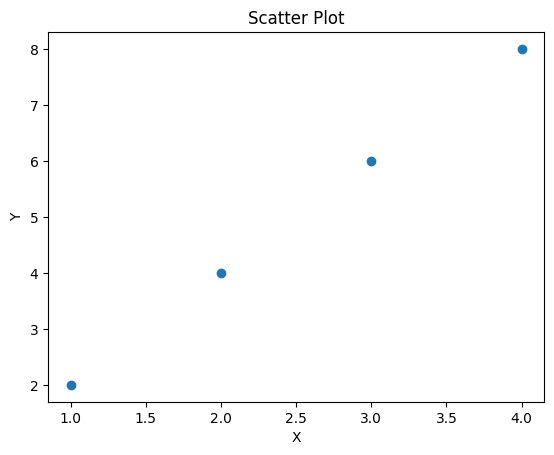

In [6]:
# Create scatter plot
plt.scatter(X, Y)

# Set labels and title
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Scatter Plot')

# The data is linear

In [9]:
n_samples, n_features = X.shape
print(f'Number of Samples: {n_samples}, Number of Features: {n_features}')

Number of Samples: 4, Number of Features: 1


In [11]:
# Setting an input or testing value
X_test = torch.tensor([5], dtype=torch.float32)
X_test

tensor([5.])

In [13]:
input_size = n_features
output_size = n_features

In [24]:
# we can call this model with samples X
model1 = nn.Linear(input_size, output_size)

In [25]:
print(f'Prediction before training: f(5) = {model1(X_test).item():.3f}')

Prediction before training: f(5) = 4.194


In [32]:
# Assigning the learning rate (alpoha) and the number of iterations
learning_rate = 0.01
n_iters = 20

In [27]:
# Defining the loss function & optimizer
loss = nn.MSELoss()
optimizer = torch.optim.SGD(model1.parameters(), lr=learning_rate)

**Training Model**

In [33]:
for epoch in range(n_iters):
    # prediction using forward pass with our model
    y_predicted = model1(X)

    # loss calculation
    l = loss(Y, y_predicted)

    # calculate gradients using backward pass
    l.backward()

    # updating weights
    optimizer.step()

    # zero the gradients after updating
    optimizer.zero_grad()

    if epoch % 2 == 0:
        [w, b] = model1.parameters() # unpacking parameters
        print('epoch ', epoch+1, ': w = ', w[0][0].item(), ' loss = ', l)

print(f'Prediction using Model 1: {model1(X_test).item():.3f}')

epoch  1 : w =  2.065592050552368  loss =  tensor(0.0063, grad_fn=<MseLossBackward0>)
epoch  3 : w =  2.065204620361328  loss =  tensor(0.0062, grad_fn=<MseLossBackward0>)
epoch  5 : w =  2.0648181438446045  loss =  tensor(0.0061, grad_fn=<MseLossBackward0>)
epoch  7 : w =  2.0644330978393555  loss =  tensor(0.0060, grad_fn=<MseLossBackward0>)
epoch  9 : w =  2.064049482345581  loss =  tensor(0.0060, grad_fn=<MseLossBackward0>)
epoch  11 : w =  2.0636675357818604  loss =  tensor(0.0059, grad_fn=<MseLossBackward0>)
epoch  13 : w =  2.0632877349853516  loss =  tensor(0.0058, grad_fn=<MseLossBackward0>)
epoch  15 : w =  2.0629100799560547  loss =  tensor(0.0057, grad_fn=<MseLossBackward0>)
epoch  17 : w =  2.0625343322753906  loss =  tensor(0.0057, grad_fn=<MseLossBackward0>)
epoch  19 : w =  2.0621607303619385  loss =  tensor(0.0056, grad_fn=<MseLossBackward0>)
Prediction using Model 1: 10.128


**Manually Creating the Linear Regression Class**

In [34]:
class LinearRegression(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LinearRegression, self).__init__()
        # define diferent layers
        self.lin = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        return self.lin(x)

model2 = LinearRegression(input_size, output_size)

In [35]:
# Assigning the learning rate (alpoha) and the number of iterations
learning_rate = 0.05
n_iters = 175

In [36]:
# Defining the loss function & optimizer
loss = nn.MSELoss()
optimizer = torch.optim.SGD(model2.parameters(), lr=learning_rate)

In [37]:
for epoch in range(n_iters):
    # predict using forward pass with our model
    y_predicted = model2(X)

    # loss calculation
    l = loss(Y, y_predicted)

    # calculate gradients using backward pass
    l.backward()

    # updating the weights
    optimizer.step()

    # zero the gradients after updating
    optimizer.zero_grad()

    if epoch % 15 == 0:
        [w, b] = model2.parameters() # unpacking parameters
        print('epoch ', epoch+1, ': w = ', w[0][0].item(), ' loss = ', l)

print(f'Prediction using Model 2: {model2(X_test).item():.3f}')

epoch  1 : w =  1.2998450994491577  loss =  tensor(49.1247, grad_fn=<MseLossBackward0>)
epoch  16 : w =  1.743251919746399  loss =  tensor(0.0981, grad_fn=<MseLossBackward0>)
epoch  31 : w =  1.795236587524414  loss =  tensor(0.0624, grad_fn=<MseLossBackward0>)
epoch  46 : w =  1.836695909500122  loss =  tensor(0.0397, grad_fn=<MseLossBackward0>)
epoch  61 : w =  1.8697606325149536  loss =  tensor(0.0252, grad_fn=<MseLossBackward0>)
epoch  76 : w =  1.8961306810379028  loss =  tensor(0.0161, grad_fn=<MseLossBackward0>)
epoch  91 : w =  1.917161464691162  loss =  tensor(0.0102, grad_fn=<MseLossBackward0>)
epoch  106 : w =  1.9339340925216675  loss =  tensor(0.0065, grad_fn=<MseLossBackward0>)
epoch  121 : w =  1.9473106861114502  loss =  tensor(0.0041, grad_fn=<MseLossBackward0>)
epoch  136 : w =  1.9579788446426392  loss =  tensor(0.0026, grad_fn=<MseLossBackward0>)
epoch  151 : w =  1.9664870500564575  loss =  tensor(0.0017, grad_fn=<MseLossBackward0>)
epoch  166 : w =  1.973272562026

In [38]:
# Setting a new input or testing value
XX_test = torch.tensor([6], dtype=torch.float32)

In [39]:
# Checking both models changing the input/test value
print(f'Prediction using Model 1: {model1(XX_test).item():.3f}')
print(f'Prediction using Model 2: {model2(XX_test).item():.3f}')

Prediction using Model 1: 12.190
Prediction using Model 2: 11.929
